<a href="https://colab.research.google.com/github/akhilkandibanda-14/OTT-Streaming-Viewing-Patterns-Genre-Association-Mining-Using-R/blob/main/OTT_Streaming_Viewing_Patterns_%26_Genre_Association_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
%%R
# Step 1: Check the R environment

cat("OTT Streaming Case Study\n")
cat("========================\n")
cat("R version:", R.version.string, "\n")
cat("Working directory:", getwd(), "\n")

# Check whether the uploaded CSV files are accessible
list.files()

OTT Streaming Case Study
R version: R version 4.6.1 (2026-06-24) 
Working directory: /content 
[1] "interactions.csv" "items_en.csv"     "sample_data"      "users_en.csv"    


In [ ]:
%%R
# STEP 2: Load the three OTT datasets

interactions <- read.csv(
  "/content/interactions.csv",
  stringsAsFactors = FALSE
)

items <- read.csv(
  "/content/items_en.csv",
  stringsAsFactors = FALSE
)

users <- read.csv(
  "/content/users_en.csv",
  stringsAsFactors = FALSE
)

# Display dataset dimensions
cat("INTERACTIONS DATASET\n")
print(dim(interactions))

cat("\nITEMS DATASET\n")
print(dim(items))

cat("\nUSERS DATASET\n")
print(dim(users))

# Display column names
cat("\nINTERACTIONS COLUMNS\n")
print(names(interactions))

cat("\nITEMS COLUMNS\n")
print(names(items))

cat("\nUSERS COLUMNS\n")
print(names(users))

INTERACTIONS DATASET
[1] 1594787       5

ITEMS DATASET
[1] 15963    17

USERS DATASET
[1] 840197      6

INTERACTIONS COLUMNS
[1] "user_id"       "item_id"       "last_watch_dt" "total_dur"    
[5] "watched_pct"  

ITEMS COLUMNS
 [1] "X"                     "item_id"               "content_type"         
 [4] "title"                 "title_orig"            "release_year"         
 [7] "genres"                "countries"             "for_kids"             
[10] "age_rating"            "studios"               "description"          
[13] "keywords"              "actors_translated"     "actors_transliterated"
[16] "directors_translated"  "transliterated"       

USERS COLUMNS
[1] "X"        "user_id"  "age"      "income"   "sex"      "kids_flg"


In [ ]:
%%R
# STEP 3A: Explore the structure of all datasets

cat("========== INTERACTIONS ==========\n")
str(interactions)
head(interactions, 6)
summary(interactions)

cat("\n========== ITEMS ==========\n")
str(items)
head(items, 6)

cat("\n========== USERS ==========\n")
str(users)
head(users, 6)


========== INTERACTIONS ==========
'data.frame':	1594787 obs. of  5 variables:
 $ user_id      : int  176549 699317 656683 864613 964868 1032142 1016458 884009 648682 203219 ...
 $ item_id      : int  9506 1659 7107 7638 9506 6686 354 693 1449 13582 ...
 $ last_watch_dt: chr  "2021-05-11" "2021-05-29" "2021-05-09" "2021-07-05" ...
 $ total_dur    : int  4250 8317 10 14483 6725 11286 1672 703 26246 6975 ...
 $ watched_pct  : num  72 100 0 100 100 100 25 14 75 100 ...

========== ITEMS ==========
'data.frame':	15963 obs. of  17 variables:
 $ X                    : int  0 1 2 3 4 5 6 7 8 9 ...
 $ item_id              : int  10711 2508 10716 7868 16268 854 1468 11114 9853 8604 ...
 $ content_type         : chr  "film" "film" "film" "film" ...
 $ title                : chr  "Talk to her" "Naked Peppers" "Tactical force" "45 years old" ...
 $ title_orig           : chr  "Hable con ella" "Search Party" "Tactical Force" "45 Years" ...
 $ release_year         : num  2002 2014 2011 2015 1978 ...

In [ ]:
%%R
# STEP 3B: Data quality report

check_data_quality <- function(df, dataset_name) {

  cat("\n==========", dataset_name, "==========\n")

  cat("Rows:", nrow(df), "\n")
  cat("Columns:", ncol(df), "\n")
  cat("Exact duplicate rows:", sum(duplicated(df)), "\n")

  missing_report <- data.frame(
    Column = names(df),
    Missing_Values = colSums(is.na(df)),
    Missing_Percentage = round(
      colMeans(is.na(df)) * 100, 4
    )
  )

  print(missing_report)
}

check_data_quality(interactions, "INTERACTIONS")
check_data_quality(items, "ITEMS")
check_data_quality(users, "USERS")



========== INTERACTIONS ==========
Rows: 1594787 
Columns: 5 
Exact duplicate rows: 0 
                     Column Missing_Values Missing_Percentage
user_id             user_id              0             0.0000
item_id             item_id              0             0.0000
last_watch_dt last_watch_dt              0             0.0000
total_dur         total_dur              1             0.0001
watched_pct     watched_pct            268             0.0168

========== ITEMS ==========
Rows: 15963 
Columns: 17 
Exact duplicate rows: 0 
                                     Column Missing_Values Missing_Percentage
X                                         X              0             0.0000
item_id                             item_id              0             0.0000
content_type                   content_type              0             0.0000
title                                 title              0             0.0000
title_orig                       title_orig              0            

In [ ]:
%%R
# STEP 3C: Analyze viewing duration and completion

cat("Viewing duration summary:\n")
print(summary(interactions$total_dur))

cat("\nWatched percentage summary:\n")
print(summary(interactions$watched_pct))

cat("\nContent types:\n")
print(table(items$content_type, useNA = "ifany"))

cat("\nMost common raw genre combinations:\n")
print(head(sort(table(items$genres), decreasing = TRUE), 10))

cat("\nDate range:\n")
print(range(
  as.Date(interactions$last_watch_dt),
  na.rm = TRUE
))


Viewing duration summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
      1     371    2900    8276    7124 7241091       1 

Watched percentage summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
   0.00    4.00   32.00   46.37  100.00  100.00     268 

Content types:

  film series 
 12002   3961 

Most common raw genre combinations:

         documentary                drama               comedy 
                 816                  719                  564 
               adult  russian, melodramas              fitness 
                 482                  416                  334 
melodramas, comedies           melodramas        drama, comedy 
                 255                  245                  233 
    drama, melodrama 
                 220 

Date range:
[1] "2021-03-13" "2021-08-22"


In [ ]:
%%R
# STEP 4A: Install and load packages

packages <- c("dplyr", "tidyr", "stringr", "ggplot2")

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org")
  }
}

library(dplyr)
library(tidyr)
library(stringr)
library(ggplot2)

cat("All required packages are ready!\n")


All required packages are ready!



Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [ ]:
%%R
# STEP 4B: Remove index-like columns if present

interactions <- interactions %>%
  select(-any_of("Unnamed: 0"))

items <- items %>%
  select(-any_of("Unnamed: 0"))

users <- users %>%
  select(-any_of("Unnamed: 0"))

cat("Index-like columns checked and removed where present.\n")

cat("Interactions:", dim(interactions), "\n")
cat("Items:", dim(items), "\n")
cat("Users:", dim(users), "\n")


Index-like columns checked and removed where present.
Interactions: 1594787 5 
Items: 15963 17 
Users: 840197 6 


In [ ]:
%%R
# STEP 4C: Normalize genre labels

items <- items %>%
  mutate(
    genres_original = genres,

    genres = str_to_lower(genres),
    genres = str_replace_all(genres, "_", " "),
    genres = str_squish(genres)
  )

# Replace clear singular/plural variants
genre_map <- c(
  "thrillers" = "thriller",
  "comedies" = "comedy",
  "dramas" = "drama",
  "melodramas" = "melodrama",
  "detectives" = "detective"
)

normalize_genre <- function(x) {

  if (is.na(x) || x == "") {
    return(NA_character_)
  }

  genres_list <- str_split(x, ",", simplify = FALSE)[[1]]
  genres_list <- str_trim(genres_list)

  genres_list <- ifelse(
    genres_list %in% names(genre_map),
    unname(genre_map[genres_list]),
    genres_list
  )

  genres_list <- unique(genres_list)

  paste(genres_list, collapse = ", ")
}

items$genres <- vapply(
  items$genres,
  normalize_genre,
  character(1)
)

cat("Original and normalized genre examples:\n")

print(
  items %>%
    select(title, genres_original, genres) %>%
    head(10)
)


Original and normalized genre examples:
                               title
1                        Talk to her
2                      Naked Peppers
3                     Tactical force
4                       45 years old
5      Everything Solves in a Moment
6                        North-South
7                 The Artistic Marya
8  Princess Swan: Pirate or Princess
9             Labyrinths of the Past
10                     Third Attempt
                                                           genres_original
1                                     drama, foreign, detective, melodrama
2                                               foreign, adventure, comedy
3                                crime, foreign, thrillers, action, comedy
4                                                drama, foreign, melodrama
5                                          drama, sport, soviet, melodrama
6                                                           drama, russian
7                  films, fa

In [ ]:
%%R
# STEP 4D: Join interactions with content metadata

ott_data <- interactions %>%
  left_join(
    items,
    by = "item_id",
    relationship = "many-to-one"
  )

cat("Integrated dataset dimensions:\n")
print(dim(ott_data))

cat("\nMissing content matches:\n")
print(sum(is.na(ott_data$title)))

cat("\nSample integrated records:\n")

print(
  ott_data %>%
    select(
      user_id,
      item_id,
      last_watch_dt,
      total_dur,
      watched_pct,
      title,
      content_type,
      genres
    ) %>%
    head(10)
)


Integrated dataset dimensions:
[1] 1594787      22

Missing content matches:
[1] 0

Sample integrated records:
   user_id item_id last_watch_dt total_dur watched_pct
1   176549    9506    2021-05-11      4250          72
2   699317    1659    2021-05-29      8317         100
3   656683    7107    2021-05-09        10           0
4   864613    7638    2021-07-05     14483         100
5   964868    9506    2021-04-30      6725         100
6  1032142    6686    2021-05-13     11286         100
7  1016458     354    2021-08-14      1672          25
8   884009     693    2021-08-04       703          14
9   648682    1449    2021-06-13     26246          75
10  203219   13582    2021-08-22      6975         100
                              title content_type
1                        Cold Heart         film
2  Three Heroes. The Ride of Horses         film
3                         Devyataev       series
4                            Michel       series
5                        Cold Heart    

In [ ]:
%%R
# STEP 4E: Validate data integration

cat("Original interaction rows:", nrow(interactions), "\n")
cat("Integrated rows:", nrow(ott_data), "\n")

cat(
  "Rows preserved:",
  nrow(interactions) == nrow(ott_data),
  "\n"
)

cat(
  "Unmatched content IDs:",
  sum(is.na(ott_data$title)),
  "\n"
)

cat("\nGenre missing-value count:\n")
print(sum(is.na(ott_data$genres)))


Original interaction rows: 1594787 
Integrated rows: 1594787 
Rows preserved: TRUE 
Unmatched content IDs: 0 

Genre missing-value count:
[1] 0


# A tibble: 15 × 2
   genres          interactions
   <chr>                  <int>
 1 drama                 670316
 2 comedy                473120
 3 thriller              432461
 4 adventure             326884
 5 action                316780
 6 melodrama             265148
 7 science fiction       196058
 8 detective             188713
 9 fantasy               167045
10 animation             126922
11 crime                 124410
12 horror                 94352
13 family                 73771
14 war                    66526
15 documentary            51824


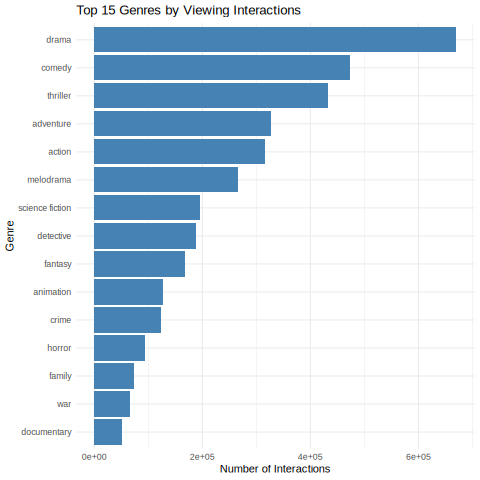

In [ ]:
%%R
# STEP 5A: Genre popularity by viewing interactions

library(dplyr)
library(tidyr)
library(ggplot2)
library(stringr)

genre_popularity <- ott_data %>%
  filter(!is.na(genres), genres != "") %>%
  separate_rows(genres, sep = ",") %>%
  mutate(genres = str_trim(genres)) %>%
  filter(!genres %in% c("no genre", "no  genre")) %>%
  count(genres, sort = TRUE, name = "interactions")

# Display the top 15 genres
print(head(genre_popularity, 15))

# Plot the top 15 genres
genre_popularity %>%
  slice_max(order_by = interactions, n = 15) %>%
  ggplot(aes(
    x = reorder(genres, interactions),
    y = interactions
  )) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Top 15 Genres by Viewing Interactions",
    x = "Genre",
    y = "Number of Interactions"
  ) +
  theme_minimal()


  content_type interactions percentage
1         film      1203984      75.49
2       series       390803      24.51


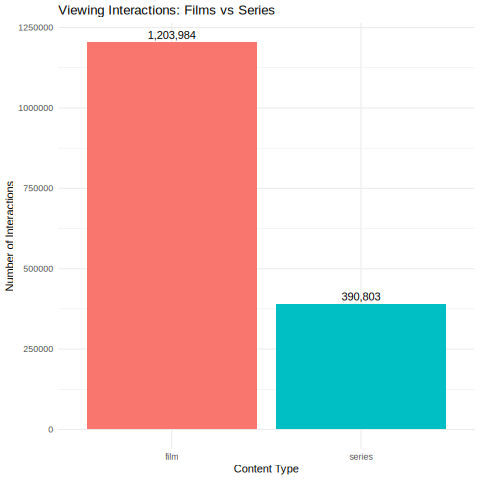

In [ ]:
%%R
# STEP 5B: Viewing interactions by content type

content_type_summary <- ott_data %>%
  filter(!is.na(content_type)) %>%
  count(content_type, name = "interactions") %>%
  mutate(
    percentage = round(
      interactions / sum(interactions) * 100, 2
    )
  )

print(content_type_summary)

ggplot(
  content_type_summary,
  aes(x = content_type, y = interactions, fill = content_type)
) +
  geom_col(show.legend = FALSE) +
  geom_text(
    aes(label = scales::comma(interactions)),
    vjust = -0.4
  ) +
  labs(
    title = "Viewing Interactions: Films vs Series",
    x = "Content Type",
    y = "Number of Interactions"
  ) +
  theme_minimal()


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      1     371    2900    8276    7124 7241091 


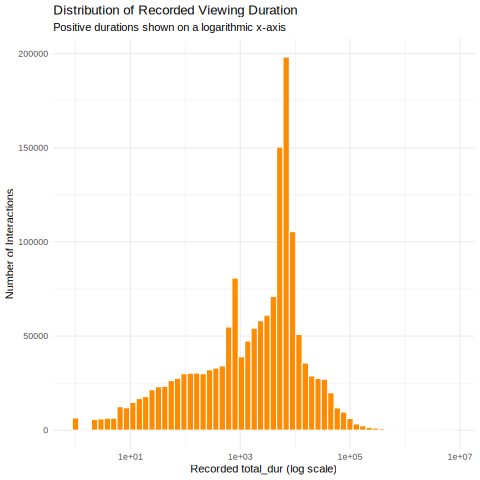

In [ ]:
%%R
# STEP 5C: Inspect viewing duration

duration_data <- ott_data %>%
  filter(
    !is.na(total_dur),
    total_dur > 0,
    is.finite(total_dur)
  )

print(summary(duration_data$total_dur))

ggplot(duration_data, aes(x = total_dur)) +
  geom_histogram(bins = 60, fill = "darkorange", color = "white") +
  scale_x_log10() +
  labs(
    title = "Distribution of Recorded Viewing Duration",
    subtitle = "Positive durations shown on a logarithmic x-axis",
    x = "Recorded total_dur (log scale)",
    y = "Number of Interactions"
  ) +
  theme_minimal()


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    4.00   32.00   46.37  100.00  100.00 


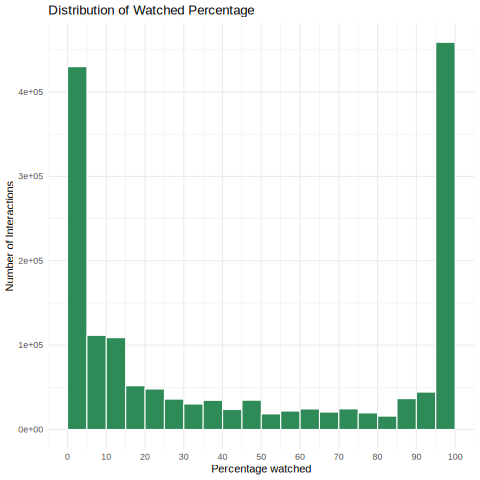

In [ ]:
%%R
# STEP 5D: Completion percentage distribution

completion_data <- ott_data %>%
  filter(
    !is.na(watched_pct),
    watched_pct >= 0,
    watched_pct <= 100
  )

print(summary(completion_data$watched_pct))

ggplot(completion_data, aes(x = watched_pct)) +
  geom_histogram(
    binwidth = 5,
    boundary = 0,
    fill = "seagreen",
    color = "white"
  ) +
  scale_x_continuous(breaks = seq(0, 100, by = 10)) +
  labs(
    title = "Distribution of Watched Percentage",
    x = "Percentage watched",
    y = "Number of Interactions"
  ) +
  theme_minimal()


# A tibble: 2 × 4
  content_type interaction_count median_duration mean_duration
  <chr>                    <int>           <int>         <dbl>
1 film                   1203983            2503         4574.
2 series                  390803            4818        19678.


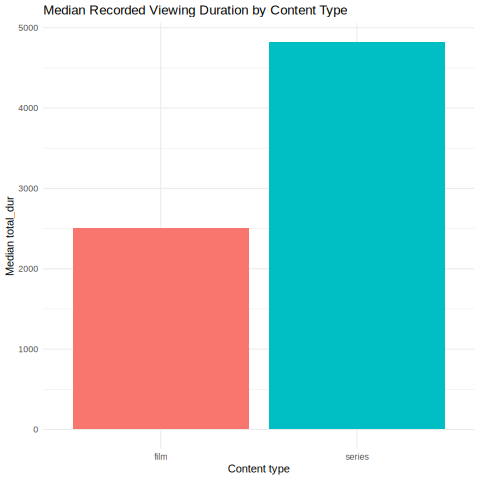

In [ ]:
%%R
# STEP 5E: Median viewing duration by content type

duration_by_type <- ott_data %>%
  filter(
    !is.na(content_type),
    !is.na(total_dur),
    total_dur > 0
  ) %>%
  group_by(content_type) %>%
  summarise(
    interaction_count = n(),
    median_duration = median(total_dur),
    mean_duration = mean(total_dur),
    .groups = "drop"
  )

print(duration_by_type)

ggplot(
  duration_by_type,
  aes(
    x = content_type,
    y = median_duration,
    fill = content_type
  )
) +
  geom_col(show.legend = FALSE) +
  labs(
    title = "Median Recorded Viewing Duration by Content Type",
    x = "Content type",
    y = "Median total_dur"
  ) +
  theme_minimal()


In [ ]:
%%R
# Ensure arules and other packages are ready
if (!requireNamespace("arules", quietly = TRUE)) {
  install.packages("arules", repos = "https://cloud.r-project.org")
}

library(dplyr)
library(tidyr)
library(stringr)
library(arules)

# Re-load and join if not present in memory
if (!exists("ott_data")) {
  cat("ott_data not found in memory. Re-loading datasets...\n")
  interactions <- read.csv("/content/interactions.csv", stringsAsFactors = FALSE) %>%
    select(-any_of("Unnamed: 0"))

  items <- read.csv("/content/items_en.csv", stringsAsFactors = FALSE) %>%
    select(-any_of("Unnamed: 0"))

  # Quick normalization of genre
  genre_map <- c("thrillers" = "thriller", "comedies" = "comedy", "dramas" = "drama", "melodramas" = "melodrama", "detectives" = "detective")

  normalize_genre <- function(x) {
    if (is.na(x) || x == "") return(NA_character_)
    genres_list <- str_trim(str_split(str_to_lower(x), ",")[[1]])
    genres_list <- str_replace_all(genres_list, "_", " ")
    genres_list <- ifelse(genres_list %in% names(genre_map), unname(genre_map[genres_list]), genres_list)
    paste(unique(genres_list), collapse = ", ")
  }

  items$genres <- vapply(items$genres, normalize_genre, character(1))

  ott_data <- interactions %>%
    left_join(items, by = "item_id", relationship = "many-to-one")
}

# Prepare distinct user-genre combinations
genre_transactions_data <- ott_data %>%
  filter(!is.na(user_id), !is.na(genres), genres != "") %>%
  select(user_id, genres) %>%
  separate_rows(genres, sep = ",") %>%
  mutate(
    genres = str_squish(str_to_lower(genres))
  ) %>%
  filter(
    genres != "",
    !genres %in% c("no genre", "no  genre")
  ) %>%
  distinct(user_id, genres)

cat("Distinct users with valid genres:",
    n_distinct(genre_transactions_data$user_id), "\n")

cat("Distinct genre labels:",
    n_distinct(genre_transactions_data$genres), "\n")

cat("\nSample user-genre records:\n")
print(head(genre_transactions_data, 10))

ott_data not found in memory. Re-loading datasets...
Distinct users with valid genres: 567568 
Distinct genre labels: 141 

Sample user-genre records:
# A tibble: 10 × 2
   user_id genres   
     <int> <chr>    
 1  176549 fantasy  
 2  176549 cartoon  
 3  176549 musical  
 4  699317 animation
 5  699317 fantasy  
 6  699317 adventure
 7  699317 comedy   
 8  656683 drama    
 9  656683 war      
10  656683 adventure


In [ ]:

%%R
library(arules)

# Group genres by user
transaction_list <- split(
  genre_transactions_data$genres,
  genre_transactions_data$user_id
)

# Remove duplicate genres within each user
transaction_list <- lapply(transaction_list, unique)

# Convert to an arules transactions object
transactions <- as(
  transaction_list,
  "transactions"
)

cat("Number of transactions:", length(transactions), "\n")
cat("Number of unique genres:", length(itemLabels(transactions)), "\n")

cat("\nTransaction size summary:\n")
print(summary(size(transactions)))

cat("\nFirst five transactions:\n")
inspect(transactions[1:5])


Number of transactions: 567568 
Number of unique genres: 141 

Transaction size summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.000   2.000   3.000   4.363   6.000  54.000 

First five transactions:
    items              transactionID
[1] {action,                        
     comedy,                        
     crime,                         
     detective,                     
     drama,                         
     horror,                        
     melodrama,                     
     thriller}                     0
[2] {action,                        
     adventure,                     
     adventures,                    
     animation,                     
     cartoon,                       
     cartoons,                      
     comedy,                        
     crime,                         
     documentary,                   
     drama,                         
     family,                        
     fantasy,                       
     melod

In [ ]:

%%R
rules <- apriori(
  transactions,
  parameter = list(
    supp = 0.01,
    conf = 0.30,
    minlen = 2,
    maxlen = 3,
    target = "rules"
  )
)

cat("Total association rules found:", length(rules), "\n")

if (length(rules) > 0) {
  inspect(head(sort(rules, by = "lift"), 10))
} else {
  cat("No rules found at these thresholds.\n")
}


Apriori

Parameter specification:
 confidence minval smax arem  aval originalSupport maxtime support minlen
        0.3    0.1    1 none FALSE            TRUE       5    0.01      2
 maxlen target  ext
      3  rules TRUE

Algorithmic control:
 filter tree heap memopt load sort verbose
    0.1 TRUE TRUE  FALSE TRUE    2    TRUE

Absolute minimum support count: 5675 

set item appearances ...[0 item(s)] done [0.00s].
set transactions ...[141 item(s), 567568 transaction(s)] done [0.25s].
sorting and recoding items ... [29 item(s)] done [0.05s].
creating transaction tree ... done [0.54s].
checking subsets of size 1 2 3 done [0.12s].
writing ... [1811 rule(s)] done [0.00s].
creating S4 object  ... done [0.20s].
Total association rules found: 1811 
     lhs                              rhs          support    confidence
[1]  {biography, crime}            => {history}    0.01467489 0.4464276 
[2]  {historical, war}             => {military}   0.01183294 0.7581847 
[3]  {biography, melodrama}

In addition: Warning message:
In apriori(transactions, parameter = list(supp = 0.01, conf = 0.3,  :
  Mining stopped (maxlen reached). Only patterns up to a length of 3 returned!


In [ ]:

%%R
library(arules)

if (length(rules) > 0) {

  # Convert rules to a data frame
  rules_df <- as(rules, "data.frame")

  # Sort by lift, then confidence
  rules_df <- rules_df[
    order(-rules_df$lift, -rules_df$confidence),
  ]

  cat("Total rules:", nrow(rules_df), "\n\n")
  cat("Top 15 rules by lift:\n")

  print(head(rules_df, 15))

} else {
  cat("No rules found. Adjust support or confidence thresholds.\n")
}


Total rules: 1811 

Top 15 rules by lift:
                                         rules    support confidence   coverage
358             {biography,crime} => {history} 0.01467489  0.4464276 0.03287183
627             {historical,war} => {military} 0.01183294  0.7581847 0.01560694
361         {biography,melodrama} => {history} 0.01656365  0.4114223 0.04025949
644          {action,historical} => {military} 0.03177593  0.7301619 0.04351901
643          {action,military} => {historical} 0.03177593  0.7683623 0.04135540
357             {crime,history} => {biography} 0.01467489  0.8326502 0.01762432
647       {adventure,historical} => {military} 0.02191808  0.6858529 0.03195740
655           {drama,military} => {historical} 0.04059602  0.7580274 0.05355482
635 {historical,science fiction} => {military} 0.01492685  0.6789550 0.02198503
656           {drama,historical} => {military} 0.04059602  0.6783748 0.05984305
367         {adventure,biography} => {history} 0.01278261  0.3754010 0.0340505

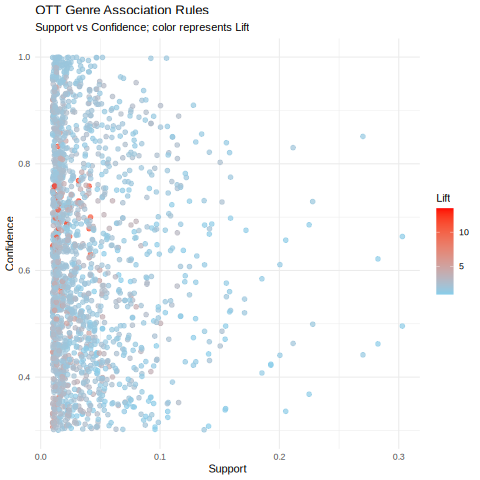

In [ ]:

%%R
library(ggplot2)

if (length(rules) > 0) {

  plot_data <- as(rules, "data.frame")

  ggplot(
    plot_data,
    aes(x = support, y = confidence, color = lift)
  ) +
    geom_point(alpha = 0.7, size = 2) +
    scale_color_gradient(low = "skyblue", high = "red") +
    labs(
      title = "OTT Genre Association Rules",
      subtitle = "Support vs Confidence; color represents Lift",
      x = "Support",
      y = "Confidence",
      color = "Lift"
    ) +
    theme_minimal()

}


In [ ]:

%%R
library(arules)
library(ggplot2)

cat("Total association rules:", length(rules), "\n")

if (length(rules) > 0) {
  rules_df <- as(rules, "data.frame")
  rules_df <- rules_df[
    order(-rules_df$lift, -rules_df$confidence),
  ]

  print(head(rules_df, 15))
} else {
  cat("No rules found. We need to adjust the thresholds.\n")
}


Total association rules: 1811 
                                         rules    support confidence   coverage
358             {biography,crime} => {history} 0.01467489  0.4464276 0.03287183
627             {historical,war} => {military} 0.01183294  0.7581847 0.01560694
361         {biography,melodrama} => {history} 0.01656365  0.4114223 0.04025949
644          {action,historical} => {military} 0.03177593  0.7301619 0.04351901
643          {action,military} => {historical} 0.03177593  0.7683623 0.04135540
357             {crime,history} => {biography} 0.01467489  0.8326502 0.01762432
647       {adventure,historical} => {military} 0.02191808  0.6858529 0.03195740
655           {drama,military} => {historical} 0.04059602  0.7580274 0.05355482
635 {historical,science fiction} => {military} 0.01492685  0.6789550 0.02198503
656           {drama,historical} => {military} 0.04059602  0.6783748 0.05984305
367         {adventure,biography} => {history} 0.01278261  0.3754010 0.03405055
624      

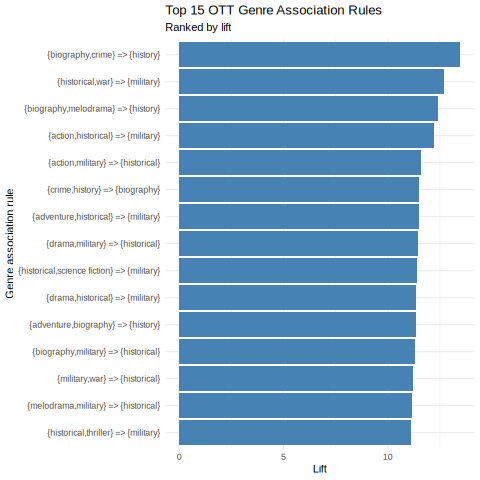

In [ ]:

%%R
if (length(rules) > 0) {

  rules_df <- as(rules, "data.frame")
  rules_df$rule_label <- as.character(rules_df$rules)

  top_rules <- head(
    rules_df[order(-rules_df$lift), ],
    15
  )

  ggplot(
    top_rules,
    aes(x = reorder(rule_label, lift), y = lift)
  ) +
    geom_col(fill = "steelblue") +
    coord_flip() +
    labs(
      title = "Top 15 OTT Genre Association Rules",
      subtitle = "Ranked by lift",
      x = "Genre association rule",
      y = "Lift"
    ) +
    theme_minimal()

}


In [ ]:

%%R
library(arules)

if (length(rules) > 0) {

  final_rules <- as(rules, "data.frame")

  final_rules <- final_rules[
    order(-final_rules$lift, -final_rules$confidence),
  ]

  # Keep the 20 strongest rules
  top20_rules <- head(final_rules, 20)

  cat("========== FINAL APRIORI RESULTS ==========\n")
  cat("Total rules discovered:", length(rules), "\n")
  cat("Rules displayed:", nrow(top20_rules), "\n\n")

  print(top20_rules)

  # Save all rules
  write.csv(
    final_rules,
    "/content/ott_genre_association_rules.csv",
    row.names = FALSE
  )

  # Save top 20 rules separately
  write.csv(
    top20_rules,
    "/content/ott_top20_genre_rules.csv",
    row.names = FALSE
  )

  cat("\nBoth CSV files have been saved in /content/.\n")

} else {
  cat("No rules are available to summarize.\n")
}


========== FINAL APRIORI RESULTS ==========
Total rules discovered: 1811 
Rules displayed: 20 

                                         rules    support confidence   coverage
358             {biography,crime} => {history} 0.01467489  0.4464276 0.03287183
627             {historical,war} => {military} 0.01183294  0.7581847 0.01560694
361         {biography,melodrama} => {history} 0.01656365  0.4114223 0.04025949
644          {action,historical} => {military} 0.03177593  0.7301619 0.04351901
643          {action,military} => {historical} 0.03177593  0.7683623 0.04135540
357             {crime,history} => {biography} 0.01467489  0.8326502 0.01762432
647       {adventure,historical} => {military} 0.02191808  0.6858529 0.03195740
655           {drama,military} => {historical} 0.04059602  0.7580274 0.05355482
635 {historical,science fiction} => {military} 0.01492685  0.6789550 0.02198503
656           {drama,historical} => {military} 0.04059602  0.6783748 0.05984305
367         {adventure,b

In [ ]:

%%R
if (length(rules) > 0) {

  quality_data <- quality(rules)

  cat("Total association rules:", length(rules), "\n")
  cat("Maximum support:", max(quality_data$support), "\n")
  cat("Maximum confidence:", max(quality_data$confidence), "\n")
  cat("Maximum lift:", max(quality_data$lift), "\n")

  cat(
    "Rules with lift > 1:",
    sum(quality_data$lift > 1),
    "\n"
  )

  cat(
    "Rules with confidence >= 0.5:",
    sum(quality_data$confidence >= 0.5),
    "\n"
  )

} else {
  cat("No association rules available.\n")
}


Total association rules: 1811 
Maximum support: 0.3030298 
Maximum confidence: 1 
Maximum lift: 13.48688 
Rules with lift > 1: 1790 
Rules with confidence >= 0.5: 1246 


In [1]:
import os

print("Files in /content:")
for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data"]]
    for file in files:
        print(os.path.join(root, file))

Files in /content:
/content/items_en.csv
/content/interactions.csv
/content/users_en.csv
